#### Data download

Downloading the two datasets for the project:
- PJM hourly energy consumption (Kaggle)
- UCI individual household electric power consumption

Files go into data/raw/

In [1]:
import os
import shutil
import zipfile
import warnings

# hide warning messages so the output is easy to read
warnings.filterwarnings("ignore")

# pandas = tables, requests = download from the internet, kagglehub = download from Kaggle
import pandas as pd
import requests
import matplotlib.pyplot as plt
import kagglehub

In [2]:
# make the folders we need. exist_ok=True means no error if the folder is already there
os.makedirs("../data/raw/uci_household", exist_ok=True)
os.makedirs("../data/raw/pjm", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../figures", exist_ok=True)

##### UCI household data

In [3]:
# why: this is the household dataset of the project (one house in France, minute readings).
# it is used to compare a single home with a whole region
uci_url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

# download the zip file only if we don't have it yet
if not os.path.exists("../data/raw/uci_household/household_power.zip"):
    # requests.get() downloads the file from the link
    r = requests.get(uci_url)
    # "wb" = write as bytes (a zip is not a text file)
    with open("../data/raw/uci_household/household_power.zip", "wb") as f:
        f.write(r.content)

# unzip the file into the same folder
if not os.path.exists("../data/raw/uci_household/household_power_consumption.txt"):
    with zipfile.ZipFile("../data/raw/uci_household/household_power.zip") as z:
        z.extractall("../data/raw/uci_household")

# show the files in the folder to check
os.listdir("../data/raw/uci_household")

['household_power_consumption.txt', 'household_power.zip']

##### PJM data

kagglehub saves it in its cache folder, so copy the files to data/raw/pjm
(if it asks for login, put kaggle.json in ~/.kaggle/)

In [4]:
# why: PJM East is the regional dataset (load of a big grid area in the US, in MW)
# download only if the pjm folder is empty
if len(os.listdir("../data/raw/pjm")) == 0:
    # dataset_download() downloads the dataset and gives back the folder where it was saved
    path = kagglehub.dataset_download("robikscube/hourly-energy-consumption")
    for f in os.listdir(path):
        # shutil.copy() copies a file from one place to another
        shutil.copy(os.path.join(path, f), "../data/raw/pjm")

os.listdir("../data/raw/pjm")

['est_hourly.paruqet',
 'PJMW_hourly.csv',
 'pjm_hourly_est.csv',
 'PJM_Load_hourly.csv',
 'DAYTON_hourly.csv',
 'NI_hourly.csv',
 'PJME_hourly.csv',
 'FE_hourly.csv',
 'DOM_hourly.csv',
 'EKPC_hourly.csv',
 'DEOK_hourly.csv',
 'DUQ_hourly.csv',
 'AEP_hourly.csv',
 'COMED_hourly.csv']

##### Check the data

In [5]:
# why: a first look at the raw data, so we know what must be cleaned in notebook 02
# read the text file. sep=";" because values are separated by ;  and "?" in the file means missing value
uci = pd.read_csv("../data/raw/uci_household/household_power_consumption.txt", sep=";", na_values="?", low_memory=False)
# join date and time into one column, e.g. 16/12/2006 + 17:24:00 -> 2006-12-16 17:24:00
uci["Datetime"] = pd.to_datetime(uci["Date"] + " " + uci["Time"], format="%d/%m/%Y %H:%M:%S")
# remove the two old columns and use the datetime as the row index
uci = uci.drop(columns=["Date", "Time"]).set_index("Datetime")
# shape = (number of rows, number of columns)
print(uci.shape)
# head() shows the first 5 rows
uci.head()

(2075259, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [6]:
# count the missing values in each column
uci.isna().sum()

Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [7]:
# parse_dates makes the Datetime column a real date, not just text
pjme = pd.read_csv("../data/raw/pjm/PJME_hourly.csv", parse_dates=["Datetime"])
# sort_index() puts the rows in time order
pjme = pjme.set_index("Datetime").sort_index()
print(pjme.shape)
pjme.head()

(145366, 1)


,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


In [8]:
# why: missing and duplicate time stamps would break the lag features and the windows later,
# so we count them here first
# summary of all files - start, end, gaps, duplicates
rows = []

# date_range() makes every minute from the first to the last time,
# so we can count how many minutes are missing in the data
full = pd.date_range(uci.index.min(), uci.index.max(), freq="min")
# one row per dataset: name, start, end, rows, missing times, duplicate times, empty values
rows.append(["UCI", uci.index.min(), uci.index.max(), len(uci),
             len(full) - uci.index.nunique(), uci.index.duplicated().sum(),
             uci["Global_active_power"].isna().sum()])

# same check for every PJM file (these are hourly)
for f in sorted(os.listdir("../data/raw/pjm")):
    # skip files that are not hourly load files
    if not f.endswith("_hourly.csv") or f == "pjm_hourly_est.csv":
        continue
    df = pd.read_csv("../data/raw/pjm/" + f, parse_dates=["Datetime"]).set_index("Datetime").sort_index()
    full = pd.date_range(df.index.min(), df.index.max(), freq="h")
    rows.append([f.replace("_hourly.csv", ""), df.index.min(), df.index.max(), len(df),
                 len(full) - df.index.nunique(), df.index.duplicated().sum(),
                 df.iloc[:, 0].isna().sum()])

# put all the rows in one table
summary = pd.DataFrame(rows, columns=["dataset", "start", "end", "rows",
                                      "missing_times", "duplicates", "nan_values"])
summary

,dataset,start,end,rows,missing_times,duplicates,nan_values
0,UCI,2006-12-16 17:24:00,2010-11-26 21:02:00,2075259,0,0,25979
1,AEP,2004-10-01 01:00:00,2018-08-03 00:00:00,121273,27,4,0
2,COMED,2011-01-01 01:00:00,2018-08-03 00:00:00,66497,11,4,0
3,DAYTON,2004-10-01 01:00:00,2018-08-03 00:00:00,121275,25,4,0
4,DEOK,2012-01-01 01:00:00,2018-08-03 00:00:00,57739,9,4,0
5,DOM,2005-05-01 01:00:00,2018-08-03 00:00:00,116189,23,4,0
6,DUQ,2005-01-01 01:00:00,2018-08-03 00:00:00,119068,24,4,0
7,EKPC,2013-06-01 01:00:00,2018-08-03 00:00:00,45334,6,4,0
8,FE,2011-06-01 01:00:00,2018-08-03 00:00:00,62874,10,4,0
9,NI,2004-05-01 01:00:00,2011-01-01 00:00:00,58450,14,0,0


In [9]:
# save the table as a csv file. index=False = don't write the row numbers
summary.to_csv("../data/processed/data_inventory.csv", index=False)

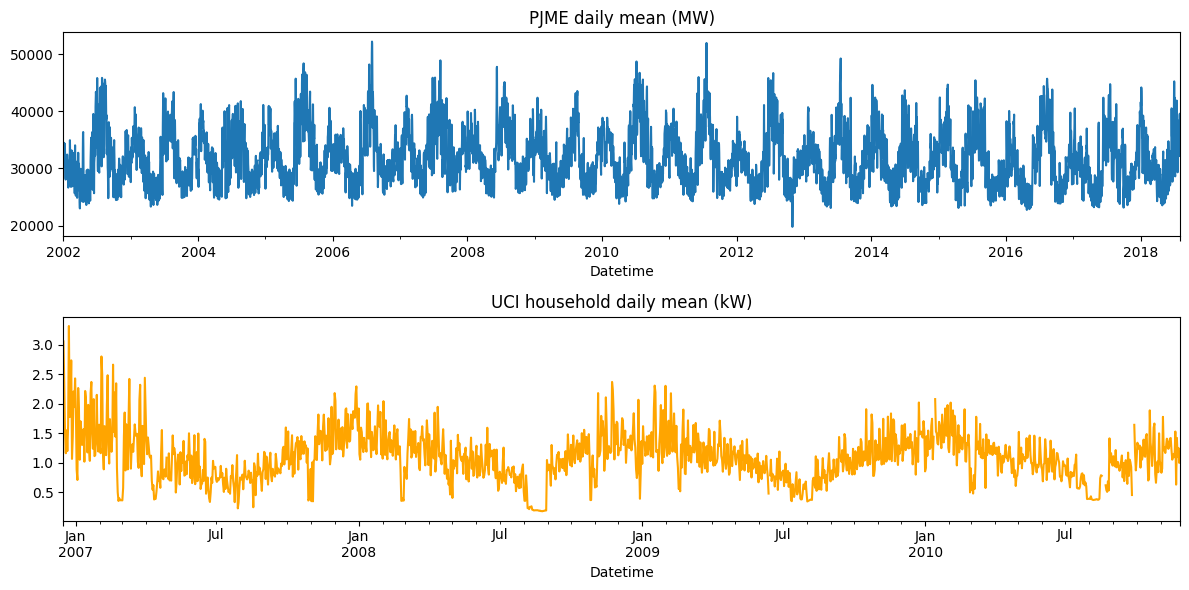

In [10]:
# why: a quick plot of the whole period shows the yearly pattern and any strange values
# 2 charts, one above the other
fig, ax = plt.subplots(2, 1, figsize=(12, 6))

# resample("D").mean() = average of each day, e.g. 24 hourly values -> 1 daily value
pjme["PJME_MW"].resample("D").mean().plot(ax=ax[0])
ax[0].set_title("PJME daily mean (MW)")

uci["Global_active_power"].resample("D").mean().plot(ax=ax[1], color="orange")
ax[1].set_title("UCI household daily mean (kW)")

# tight_layout() fixes the spacing so titles don't overlap
plt.tight_layout()
# save the chart as a png. dpi=150 is the image quality
plt.savefig("../figures/01_daily_mean_load.png", dpi=150, bbox_inches="tight")
plt.show()